In [1]:
#Packages
import os
import pandas as pd
from pathlib import Path

# Directory
directory = r"C:\Users\20234503\Desktop\Research\Weather and Strikes\Project\Results_2"

# Labour Conflict
labour_h1 = pd.read_csv(os.path.join(directory, "Raw", "hot_day_1_labour_unrest.csv"))
labour_h2    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_2_labour_unrest.csv"))
labour_h3    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_3_labour_unrest.csv"))

# Protests
protests_h1 = pd.read_csv(os.path.join(directory, "Raw", "hot_day_1_protest.csv"))
protests_h2    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_2_protest.csv"))
protests_h3    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_3_protest.csv"))

# Strikes
strikes_h1 = pd.read_csv(os.path.join(directory, "Raw", "hot_day_1_strike.csv"))
strikes_h2    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_2_strike.csv"))
strikes_h3    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_3_strike.csv"))

# Strikes (by Climate Region!)
strikes_h1_CDD1 = pd.read_csv(os.path.join(directory, "Raw", "hot_day_1_strike_CDD1.csv"))
strikes_h1_CDD2 = pd.read_csv(os.path.join(directory, "Raw", "hot_day_1_strike_CDD2.csv"))
strikes_h2_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_2_strike_CDD1.csv"))
strikes_h2_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_2_strike_CDD2.csv"))
strikes_h3_CDD1    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_3_strike_CDD1.csv"))
strikes_h3_CDD2    = pd.read_csv(os.path.join(directory, "Raw", "hot_day_3_strike_CDD2.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[[2]].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

labour_h1 = clean_df(labour_h1)
labour_h2 = clean_df(labour_h2)
labour_h3 = clean_df(labour_h3)

strikes_h1 = clean_df(strikes_h1)
strikes_h2 = clean_df(strikes_h2)
strikes_h3 = clean_df(strikes_h3)

strikes_h1_CDD1 = clean_df(strikes_h1_CDD1)
strikes_h1_CDD2 = clean_df(strikes_h1_CDD2)
strikes_h2_CDD1 = clean_df(strikes_h2_CDD1)
strikes_h2_CDD2 = clean_df(strikes_h2_CDD2)
strikes_h3_CDD1 = clean_df(strikes_h3_CDD1)
strikes_h3_CDD2 = clean_df(strikes_h3_CDD2)

protests_h1 = clean_df(protests_h1)
protests_h2 = clean_df(protests_h2)
protests_h3 = clean_df(protests_h3)


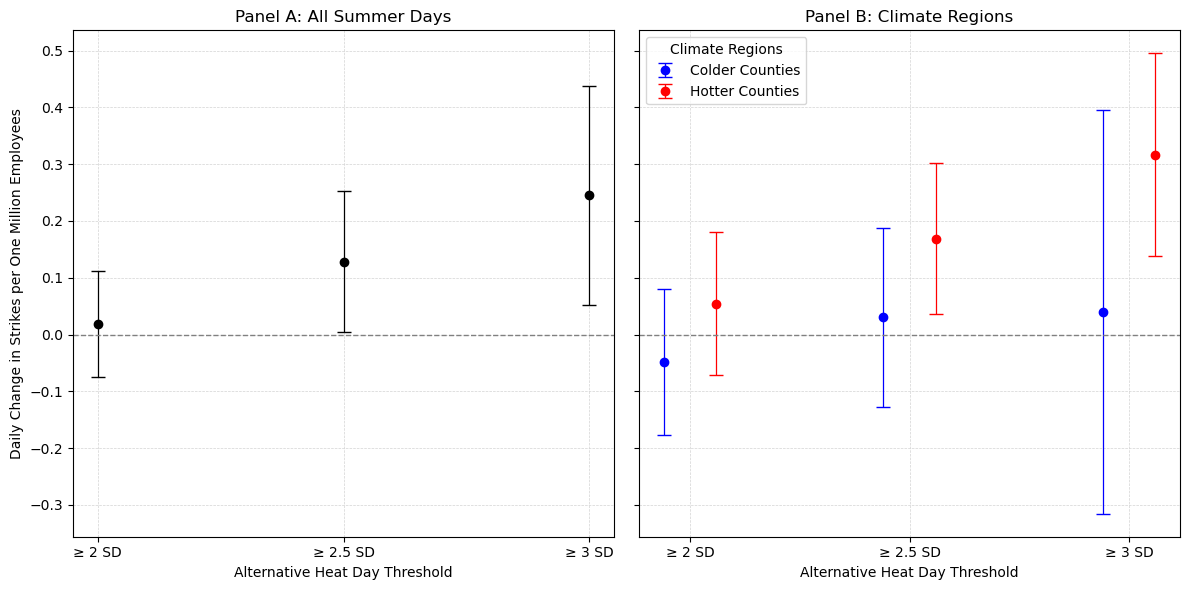

In [5]:
# Effect by Changing Threshold (Summer Strikes)- by All Summer Days, Hot Region, Cold Region #
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define thresholds and variable names
thresholds = {
    "≥ 2 SD":   {"All Summer Days": strikes_h1,   "Colder Counties": strikes_h1_CDD1,   "Hotter Counties": strikes_h1_CDD2,   "var": "hot_day_1"},
    "≥ 2.5 SD": {"All Summer Days": strikes_h2,   "Colder Counties": strikes_h2_CDD1,   "Hotter Counties": strikes_h2_CDD2,   "var": "hot_day_2"},
    "≥ 3 SD":   {"All Summer Days": strikes_h3,   "Colder Counties": strikes_h3_CDD1,   "Hotter Counties": strikes_h3_CDD2,   "var": "hot_day_3"},
}

# Outcome labels
outcome_labels = {
    "All Summer Days":   "All Summer Days",
    "Colder Counties": "Colder Counties",
    "Hotter Counties":  "Hotter Counties",
}

# Extract rows for plotting
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for outcome_key in ["All Summer Days", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            outcome_labels[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df = pd.DataFrame(rows, columns=["threshold", "outcome", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

threshold_list = list(plot_df["threshold"].unique())
# Fix the order explicitly if needed:
# threshold_list = ["≥ 2 SD", "≥ 2.5 SD", "≥ 3 SD"]
x = np.arange(len(threshold_list))

outcome_colors = {
    "All Summer Days": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

# ---------- Panel A: All Summer Days ----------
axA = axes[0]
df_all = (
    plot_df[plot_df["outcome"] == "All Summer Days"]
    .set_index("threshold")
    .loc[threshold_list]
)

axA.errorbar(
    x,
    df_all["est"],
    yerr=[
        df_all["est"] - df_all["ci_low"],
        df_all["ci_high"] - df_all["est"],
    ],
    fmt="o",
    capsize=5,
    linewidth=0.9,
    color=outcome_colors["All Summer Days"],
    ecolor=outcome_colors["All Summer Days"],
    mec=outcome_colors["All Summer Days"],
    mfc=outcome_colors["All Summer Days"],
    label="All Summer Days",
)

axA.axhline(0, color="grey", linestyle="--", linewidth=1)
axA.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axA.set_xticks(x)
axA.set_xticklabels(threshold_list)
axA.set_xlabel("Alternative Heat Day Threshold")
axA.set_ylabel("Daily Change in Strikes per One Million Employees")
axA.set_title("Panel A: All Summer Days")
#axA.legend()

# ---------- Panel B: By Climate Region ----------
axB = axes[1]

offset = 0.12   # controls spacing between the two groups

for i, outcome in enumerate(["Colder Counties", "Hotter Counties"]):
    df_sub = (
        plot_df[plot_df["outcome"] == outcome]
        .set_index("threshold")
        .loc[threshold_list]
    )

    colour = outcome_colors[outcome]

    # Apply offset: colder = -offset, hotter = +offset
    x_pos = x + (i - 0.5) * (2 * offset)

    axB.errorbar(
        x_pos,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

axB.axhline(0, color="grey", linestyle="--", linewidth=1)
axB.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

axB.set_xticks(x)
axB.set_xticklabels(threshold_list)
axB.set_xlabel("Alternative Heat Day Threshold")
axB.set_title("Panel B: Climate Regions")
axB.legend(title="Climate Regions")

plt.tight_layout()
plt.show()


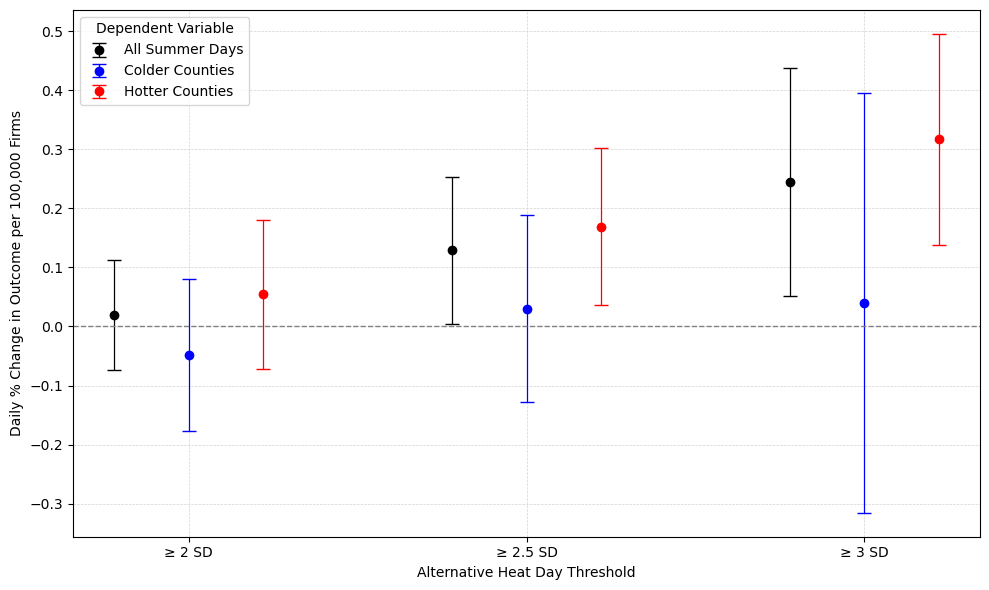

In [5]:
# Effect by Changing Threshold (Summer Strikes)- by All Summer Days, Hot Region, Cold Region #
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define thresholds and variable names
thresholds = {
    "≥ 2 SD":   {"All Summer Days": strikes_h1,   "Colder Counties": strikes_h1_CDD1,   "Hotter Counties": strikes_h1_CDD2,   "var": "hot_day_1"},
    "≥ 2.5 SD": {"All Summer Days": strikes_h2,   "Colder Counties": strikes_h2_CDD1,   "Hotter Counties": strikes_h2_CDD2,   "var": "hot_day_2"},
    "≥ 3 SD":   {"All Summer Days": strikes_h3,   "Colder Counties": strikes_h3_CDD1,   "Hotter Counties": strikes_h3_CDD2,   "var": "hot_day_3"},
}

# Outcome labels
outcome_labels = {
    "All Summer Days":   "All Summer Days",
    "Colder Counties": "Colder Counties",
    "Hotter Counties":  "Hotter Counties",
}

# Extract rows for plotting
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for outcome_key in ["All Summer Days", "Colder Counties", "Hotter Counties"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            outcome_labels[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df = pd.DataFrame(rows, columns=["threshold", "outcome", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

plt.figure(figsize=(10, 6))

threshold_list = list(plot_df["threshold"].unique())
outcome_list   = list(plot_df["outcome"].unique())

N = len(threshold_list)
M = len(outcome_list)

x = np.arange(N)
width = 0.22   # spacing between outcomes within each threshold

# Fixed colours by outcome
outcome_colors = {
    "All Summer Days": "black",
    "Colder Counties": "blue",
    "Hotter Counties": "red",
}

for i, outcome in enumerate(outcome_list):
    df_sub = plot_df[plot_df["outcome"] == outcome].set_index("threshold").loc[threshold_list]

    colour = outcome_colors[outcome]

    plt.errorbar(
        x + (i - (M-1)/2) * width,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colour,
        ecolor=colour,
        mec=colour,
        mfc=colour,
        label=outcome,
    )

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

plt.xticks(x, threshold_list)
plt.xlabel("Alternative Heat Day Threshold")
plt.ylabel("Daily % Change in Outcome per 100,000 Firms")
plt.legend(title="Dependent Variable")
plt.tight_layout()
plt.show()

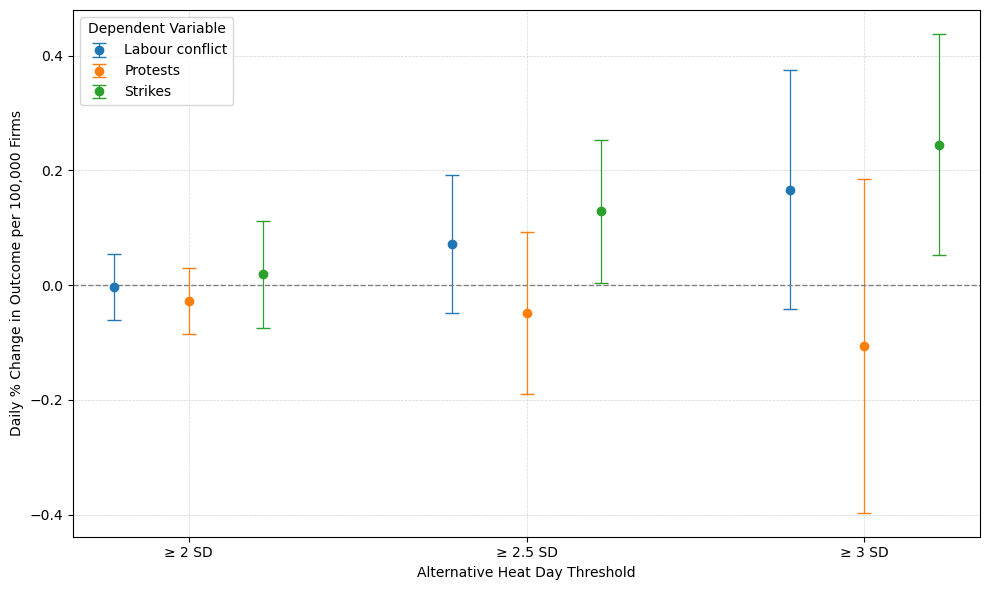

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Define thresholds and variable names
thresholds = {
    "≥ 2 SD":   {"labour": labour_h1,   "protests": protests_h1,   "strikes": strikes_h1,   "var": "hot_day_1"},
    "≥ 2.5 SD": {"labour": labour_h2,   "protests": protests_h2,   "strikes": strikes_h2,   "var": "hot_day_2"},
    "≥ 3 SD":   {"labour": labour_h3,   "protests": protests_h3,   "strikes": strikes_h3,   "var": "hot_day_3"},
}

# Outcome labels
outcome_labels = {
    "labour":   "Labour conflict",
    "protests": "Protests",
    "strikes":  "Strikes",
}

# Extract rows for plotting
rows = []

for thresh_label, info in thresholds.items():
    varname = info["var"]

    for outcome_key in ["labour", "protests", "strikes"]:
        df = info[outcome_key]
        sub = df[df["Variable"] == varname]

        if sub.empty:
            print(f"⚠ Warning: {varname} not found in {outcome_key} at {thresh_label}")
            continue

        row = sub.iloc[0]
        est = row["est"]
        se  = row["se"]

        ci_low  = est - 1.96 * se
        ci_high = est + 1.96 * se

        rows.append([
            thresh_label,
            outcome_labels[outcome_key],
            est,
            ci_low,
            ci_high
        ])

plot_df = pd.DataFrame(rows, columns=["threshold", "outcome", "est", "ci_low", "ci_high"])

# -------------------- PLOTTING --------------------

plt.figure(figsize=(10, 6))

threshold_list = list(plot_df["threshold"].unique())
outcome_list   = list(plot_df["outcome"].unique())

N = len(threshold_list)
M = len(outcome_list)

x = np.arange(N)
width = 0.22   # spacing between outcomes within each threshold

# Get colour cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color'][:M]

for i, outcome in enumerate(outcome_list):
    df_sub = plot_df[plot_df["outcome"] == outcome].set_index("threshold").loc[threshold_list]

    plt.errorbar(
        x + (i - (M-1)/2) * width,
        df_sub["est"],
        yerr=[
            df_sub["est"] - df_sub["ci_low"],
            df_sub["ci_high"] - df_sub["est"],
        ],
        fmt="o",
        capsize=5,
        linewidth=0.9,
        color=colors[i],   # ← different colour per outcome
        ecolor=colors[i],
        mec=colors[i],
        mfc=colors[i],
        label=outcome,
    )

plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

plt.xticks(x, threshold_list)
plt.xlabel("Alternative Heat Day Threshold")
plt.ylabel("Daily % Change in Outcome per 100,000 Firms")
plt.legend(title="Dependent Variable")
plt.tight_layout()
plt.show()
